# Episode 3: Your First Real Dataset (Restaurant Bills)
**Data Science with Isa · Hire-Ready Data Science**

**Business question:** Which day brings the restaurant the most revenue?

We use seaborn's built-in **tips** dataset: 244 restaurant bills. No data file is needed, because seaborn downloads it for you (internet is needed the first time).

Run the cells from top to bottom. Each step has a short explanation above it.

## 0. Setup
We import three libraries:
- **pandas** for tables (DataFrames) and analysis
- **seaborn** for the example `tips` dataset
- **matplotlib** to draw and save the chart

If a library is missing, run `%pip install pandas seaborn matplotlib` in a cell, then restart the kernel.

Tip: if a cell shows `[*]` and nothing happens, the kernel is busy or stuck. Wait a bit, or use **Kernel → Interrupt**, then **Restart**.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## 1. Load and look
`sns.load_dataset("tips")` loads the data into a DataFrame called `df`, which is a table with rows and columns.

`df.shape` gives **(rows, columns)**. We expect **(244, 7)**.

In [2]:
df = sns.load_dataset("tips")
df.shape

(244, 7)

`df.head()` shows the first 5 rows, so we can see what the data looks like.

In [3]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


`df.dtypes` (say "D-types") shows the type of each column:
- **float**: decimal numbers (`total_bill`, `tip`)
- **int**: whole numbers (`size`, the number of people at the table)
- **category**: fixed labels (`sex`, `smoker`, `day`, `time`)

➡️ The revenue for each bill is in **`total_bill`**.

In [4]:
df.dtypes

total_bill     float64
tip            float64
sex           category
smoker        category
day           category
time          category
size             int64
dtype: object

## 2. Data quality
Before answering the question, we check that the data can be trusted.

`df.isna().sum()` counts the missing values in each column. Each missing value is `True`, and `True` counts as 1. Result: **0 missing values**.

In [5]:
df.isna().sum()

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

`df.duplicated().sum()` counts rows that are exact copies of an earlier row. Result: **1 duplicate**.

In [6]:
df.duplicated().sum()

np.int64(1)

`df[df.duplicated(keep=False)]` shows **both** copies (`keep=False` marks every copy).

`df[mask]` means "keep only the rows where the mask is `True`". This is called **boolean filtering**.

➡️ **We keep the duplicate.** There's no bill ID, so two identical small bills can really happen. Only remove data when you have a clear reason.

In [7]:
df[df.duplicated(keep=False)]

,total_bill,tip,sex,smoker,day,time,size
198,13.0,2.0,Female,Yes,Thur,Lunch,2
202,13.0,2.0,Female,Yes,Thur,Lunch,2


## 3. Which days are in the data?
`day` is a category column. `.cat.categories` lists its labels.

The data only has **4 days: Thur, Fri, Sat, Sun**. That's an important limit to remember.

In [8]:
df["day"].cat.categories.tolist()

['Thur', 'Fri', 'Sat', 'Sun']

## 4. New column: tip percentage
This line calculates the tip percentage for **every row at once**, with no loop. This is called **vectorization**.

Example: a \$3 tip on a \$20 bill is 3 ÷ 20 × 100 = **15%**.

In [9]:
df["tip_pct"] = df["tip"] / df["total_bill"] * 100
df[["total_bill", "tip", "tip_pct"]].head().round(2)

,total_bill,tip,tip_pct
0,16.99,1.01,5.94
1,10.34,1.66,16.05
2,21.01,3.50,16.66
3,23.68,3.31,13.98
4,24.59,3.61,14.68


## 5. groupby + agg (the key step): split, calculate, combine
- `groupby("day", observed=True)` **splits** the rows into one group per day. `observed=True` keeps only the days that actually appear.
- `.agg()` (aggregate) **squeezes** many values into one summary number per group. Each line reads `new_name=("column", "function")`:
  - `revenue=("total_bill", "sum")` is the total money per day
  - `bills=("total_bill", "size")` is the number of bills per day
  - `avg_bill=("total_bill", "mean")` is the average bill per day
  - `avg_tip_pct=("tip_pct", "mean")` is the average tip % per day

**Why `.agg()` and not just `.sum()`?** It runs several calculations at once and lets you name the result columns.

**Mini example:** Saturday bills 10 and 20 give sum 30, count 2, mean 15. Sunday bills 5, 15 and 25 give sum 45, count 3, mean 15. The average is the same, but the totals are different, which is why we calculate both.

In [10]:
by_day = df.groupby("day", observed=True).agg(
    revenue=("total_bill", "sum"),
    bills=("total_bill", "size"),
    avg_bill=("total_bill", "mean"),
    avg_tip_pct=("tip_pct", "mean"),
)
by_day.round(2)

,revenue,bills,avg_bill,avg_tip_pct
day,,,,
Thur,1096.33,62,17.68,16.13
Fri,325.88,19,17.15,16.99
Sat,1778.40,87,20.44,15.32
Sun,1627.16,76,21.41,16.69


### Share of revenue and share of bills
- **Revenue share %**: each day's revenue ÷ total revenue × 100
- **Bill share %**: each day's number of bills ÷ all 244 bills × 100

`.round(2)` keeps 2 decimals so the table is easy to read.

In [11]:
by_day["revenue_share_%"] = (by_day["revenue"] / by_day["revenue"].sum() * 100).round(2)
by_day["bill_share_%"] = (by_day["bills"] / by_day["bills"].sum() * 100).round(2)
by_day.round(2)

,revenue,bills,avg_bill,avg_tip_pct,revenue_share_%,bill_share_%
day,,,,,,
Thur,1096.33,62,17.68,16.13,22.71,25.41
Fri,325.88,19,17.15,16.99,6.75,7.79
Sat,1778.40,87,20.44,15.32,36.84,35.66
Sun,1627.16,76,21.41,16.69,33.70,31.15


Overall numbers for the whole dataset: total revenue, average bill and average tip %.

In [12]:
print("Total revenue:", round(df["total_bill"].sum(), 2))
print("Average bill:", round(df["total_bill"].mean(), 2))
print("Average tip %:", round(df["tip_pct"].mean(), 2))

Total revenue: 4827.77
Average bill: 19.79
Average tip %: 16.08


## 6. Chart
One simple bar chart makes the answer clear at a glance.
- `plot(kind="bar")` draws the bars
- `title` and `ylabel` explain what we're looking at
- `tight_layout()` stops labels getting cut off
- `savefig()` saves the chart as a PNG file

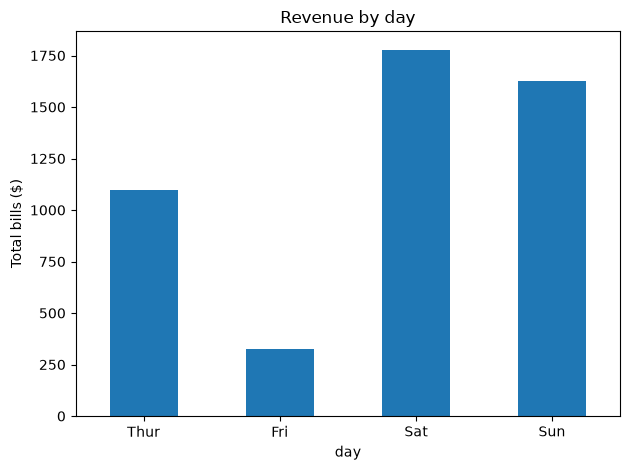

In [13]:
by_day["revenue"].plot(kind="bar", title="Revenue by day", rot=0)
plt.ylabel("Total bills ($)")
plt.tight_layout()
plt.savefig("revenue_by_day.png")
plt.show()

## 📊 Result
- **Saturday** brings in the most money: **\$1,778.40** (36.84%, about 37% of revenue).
- **Sunday** is close behind with **\$1,627.16** (33.70%) and has the **highest average bill: \$21.41**.
- Thursday: \$1,096.33. Friday: \$325.88.
- Total revenue: **\$4,827.77**. Average bill: **\$19.79**. Average tip: **about 16%**.

## ⚠️ Limits
Only 4 days, one waiter and 244 bills. This is a small sample, so it can't describe a whole real week or every restaurant.

## Next question?
What would you ask next? For example: does lunch or dinner bring more revenue? Share your answer in the YouTube comments!